# Advanced Algorithms: Amortized and Randomized Algorithms

> **Prerequisite:** [`dsa/01` Complexity analysis and recursion](../dsa/01_complexity_analysis_and_recursion.ipynb) (Big-O, recurrences, the `list.append` example of amortized cost).
>
> **Who is this for:** you have finished the core DSA notebooks and want the next level, the material a second algorithms course (or an MS qualifying exam) covers. It is also for interview preparation at companies that ask "why is this O(1) amortized?" or "how would you pick a random pivot?".
>
> **What you will learn:**
> - The three ways to do **amortized analysis** (aggregate, accounting, potential), each with a worked proof. Examples: a binary counter, a stack with `multipop`, and a growable array (and why growing ×2 beats growing +k, with measured timings)
> - **Union-find** with union by rank and path compression, with pointer hops counted and compared against the inverse Ackermann function α(n)
> - **Las Vegas vs Monte Carlo** algorithms, and expected vs worst-case running time
> - **Randomized quicksort** and **quickselect**, with the measured distribution of comparisons
> - **Universal hashing**: build a family, check its collision bound, and beat an adversary that breaks Python's integer `hash`
> - **Skip lists** and **treaps** from scratch (insert, search, delete), benchmarked against `bisect` on a sorted list
> - **Miller–Rabin** primality testing and its error probability
> - **Karger's min-cut** and probability amplification by repetition
> - How randomness powers modern AI: random restarts, SGD and **randomized SVD**
>
> **Prerequisites:** [Python basics](../../01_Python/01_basic.ipynb); [`dsa/01`](../dsa/01_complexity_analysis_and_recursion.ipynb); basic probability (expected value, independent events). The [probability notebook](../../14_Mathematics/03_probability.ipynb) is a good refresher.
>
> **Time needed:** about 3 hours.
>
> **Runs on:** CPU, no API key, no internet. The whole notebook runs in about a minute.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep. It follows CLRS (4th ed.) ch. 16 (amortized analysis), ch. 19 (disjoint sets) and the randomized parts of ch. 7, 9 and 11, plus Motwani & Raghavan, *Randomized Algorithms*.

## Explained simply

Some operations are usually cheap but occasionally expensive. **Amortized analysis** asks: if I do a long run of them, what is the cost *per operation* on average? Think of a monthly bus pass. Buying it is one big payment, but spread over 30 days each ride is cheap. Another everyday example is a growing bookshelf: when your shelf is full you buy a shelf twice as big and move all the books once. Moving is painful, but it happens so rarely that, per book, it costs almost nothing.

The second half of the notebook is about algorithms that **flip coins**. It sounds strange, but randomness protects you from bad luck: if you always pick the first person in a queue to split a group, someone can arrange the queue to trick you; if you pick at random, nobody can. Shuffling a deck before dealing cards works the same way.

**Tiny example.** Count from 0 to 8 in binary: 0000, 0001, 0010, 0011, 0100, 0101, 0110, 0111, 1000. Count the digits that change each time: 1, 2, 1, 3, 1, 2, 1, 4. One step (0111 → 1000) changes 4 digits, but the total over 8 steps is 15, which is less than 2 per step on average.

**In one line**

| Concept | Simple meaning | Where you see it in real life/AI |
|---|---|---|
| Amortized cost | the average cost per step over the worst possible run of steps | Python's `list.append`, hash tables resizing |
| Randomized (Las Vegas) algorithm | always right, uses coin flips to be fast on every input | random pivot in quicksort, skip lists in Redis |
| Monte Carlo algorithm | always fast, with a tiny, controllable chance of being wrong | prime tests that create encryption keys, SGD in deep learning |

### How this notebook is different from `dsa/01`
[`dsa/01`](../dsa/01_complexity_analysis_and_recursion.ipynb) shows *that* `list.append` is O(1) amortized, using the aggregate method once. Here we go further:
- we learn the two other methods (accounting and potential), which are the ones exams ask you to use for proofs;
- we apply all three methods to several data structures;
- we then study a second big idea: algorithms that **flip coins** to be simpler, faster or harder to attack.

## Table of contents
1. Amortized analysis: aggregate, accounting and potential methods
2. Dynamic arrays: why ×2 beats +k
3. Union-find with union by rank and path compression
4. Randomized algorithms: Las Vegas vs Monte Carlo
5. Randomized quicksort and quickselect
6. Universal hashing
7. Skip lists
8. Treaps
9. Miller–Rabin primality testing
10. Karger's randomized min-cut
11. Summary table
12. How this connects to modern AI
13. Recap, practice problems, further reading

In [1]:
# Standard setup used throughout this notebook
import random, math, time, timeit, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)          # reproducible random numbers (Python)
np.random.seed(42)       # reproducible random numbers (NumPy)

# One consistent, colour-blind-friendly palette for every chart in this module
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.titleweight": "bold", "figure.dpi": 100,
})
pd.set_option("display.width", 140)
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)

from collections import Counter, defaultdict
import bisect
import networkx as nx

Python 3.12.3 | numpy 2.4.6 | pandas 2.3.3


---
## 1. Amortized analysis

> 💬 **In plain English:** some operations are expensive now and then; we prove that, averaged over any long run, each one is still cheap.

**Intuition.** You pay rent once a month, not every day. Spread over 30 days, the cost per day is small, even though one day in the month is expensive. **Amortized analysis** does the same with operations on a data structure: a few operations are expensive, but if they are rare enough, the **average cost per operation over the worst possible sequence** is small.

**Definition.** The **amortized cost** of an operation is an upper bound such that, for *every* sequence of n operations,

$$\sum_{i=1}^{n} c_i \;\le\; \sum_{i=1}^{n} \hat c_i ,$$

where $c_i$ is the actual cost of operation i and $\hat c_i$ is its amortized cost.

> ⚠️ **Common mistake:** amortized ≠ average case. Average-case analysis assumes a *probability distribution over inputs*. Amortized analysis makes **no probabilistic assumption**: the bound holds for the worst sequence of operations. It is a guarantee about totals, not a guess about typical inputs.

There are three standard methods (CLRS ch. 16):

| Method | Idea | What you must show |
|---|---|---|
| **Aggregate** | add up the total cost T(n) of the worst n-operation sequence and divide by n | T(n) = O(f(n)) |
| **Accounting** (banker's) | charge each operation a fixed "price" $\hat c_i$; extra money is stored as **credit** on parts of the data structure and pays for later expensive work | the credit never goes negative |
| **Potential** (physicist's) | define a function Φ (the "stored energy") of the whole data structure; $\hat c_i = c_i + \Phi(D_i) - \Phi(D_{i-1})$ | Φ(D₀) = 0 and Φ(D_i) ≥ 0 for all i |

Why the potential method works: summing $\hat c_i$ makes the Φ terms **telescope**:

$$\sum_{i=1}^{n} \hat c_i = \sum_{i=1}^{n} c_i + \Phi(D_n) - \Phi(D_0) \;\ge\; \sum_{i=1}^{n} c_i \quad\text{because } \Phi(D_n) \ge 0 = \Phi(D_0).$$

### 1a. Example 1: a binary counter

A k-bit counter stored as an array of bits. `increment` flips trailing 1s to 0 and then one 0 to 1. The **cost** is the number of bit flips.

Worked example by hand (4 bits, the rightmost bit is bit 0):

| value | bits | flips for this increment | total so far | 2 × (increments) |
|---|---|---|---|---|
| 0 | 0000 | – | 0 | 0 |
| 1 | 0001 | 1 | 1 | 2 |
| 2 | 0010 | 2 | 3 | 4 |
| 3 | 0011 | 1 | 4 | 6 |
| 4 | 0100 | 3 | 7 | 8 |
| 5 | 0101 | 1 | 8 | 10 |
| 6 | 0110 | 2 | 10 | 12 |
| 7 | 0111 | 1 | 11 | 14 |
| 8 | 1000 | 4 | 15 | 16 |

One increment can cost k flips (0111…1 → 1000…0), so a naive bound for n increments is O(nk). But the total stays below 2n. The three proofs:

- **Aggregate.** Bit 0 flips every time (n times), bit 1 every 2nd time (⌊n/2⌋), bit j every 2ʲ-th time. Total ≤ n(1 + ½ + ¼ + …) < **2n**, so each increment is **O(1) amortized**.
- **Accounting.** Charge **2** per increment. Spend 1 to set a bit to 1 and leave 1 coin of credit *on that bit*. When a 1 is later reset to 0, its stored coin pays for the flip. Every 1-bit always carries a coin, so the credit is never negative.
- **Potential.** Let Φ = number of 1-bits. If an increment resets t bits and sets one bit, then c = t + 1 and ΔΦ = 1 − t, so $\hat c = (t+1) + (1-t) = 2$. Φ starts at 0 and is never negative, so the total is at most 2n.

first 8 actual costs:       [1, 2, 1, 3, 1, 2, 1, 4]  (matches the hand table)
max single increment cost:  10
total flips for 1000 incs:  1994 <= 2n = 2000
every amortized cost == 2?  True


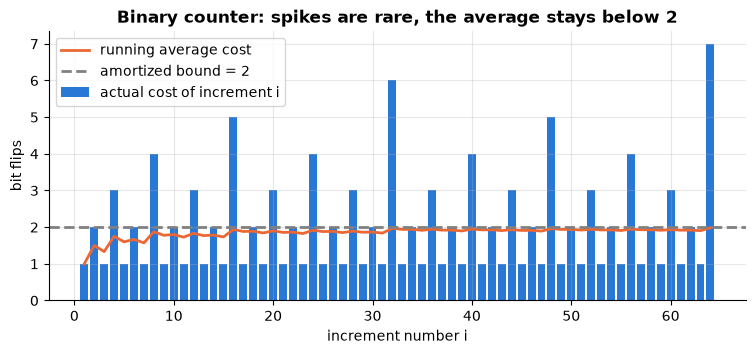

In [2]:
class BinaryCounter:
    """A k-bit binary counter that records the cost (bit flips) of each increment."""
    def __init__(self, k):
        self.bits = [0] * k          # bits[0] is the least significant bit

    def potential(self):
        return sum(self.bits)        # Φ = number of 1-bits

    def increment(self):
        flips = 0
        i = 0
        while i < len(self.bits) and self.bits[i] == 1:   # reset trailing 1s
            self.bits[i] = 0
            flips += 1
            i += 1
        if i < len(self.bits):       # set the first 0 to 1 (unless we overflowed)
            self.bits[i] = 1
            flips += 1
        return flips

counter = BinaryCounter(k=16)
actual, amortized = [], []
for _ in range(1000):
    phi_before = counter.potential()
    c = counter.increment()                      # actual cost c_i
    phi_after = counter.potential()
    actual.append(c)
    amortized.append(c + phi_after - phi_before) # potential method: ĉ_i = c_i + ΔΦ

print("first 8 actual costs:      ", actual[:8], " (matches the hand table)")
print("max single increment cost: ", max(actual))
print("total flips for 1000 incs: ", sum(actual), "<= 2n =", 2 * 1000)
print("every amortized cost == 2? ", set(amortized) == {2})
assert actual[:8] == [1, 2, 1, 3, 1, 2, 1, 4]
assert sum(actual) <= 2 * len(actual) and set(amortized) == {2}

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(range(1, 65), actual[:64], color=PALETTE[0], label="actual cost of increment i")
ax.plot(range(1, 65), np.cumsum(actual[:64]) / np.arange(1, 65), color=PALETTE[1],
        label="running average cost")
ax.axhline(2, ls="--", color="gray", label="amortized bound = 2")
ax.set(xlabel="increment number i", ylabel="bit flips", title="Binary counter: spikes are rare, the average stays below 2")
ax.legend(); plt.show()

**What just happened?** The actual costs spike (1, 2, 1, 3, 1, 2, 1, 4, …: the spike at i is 1 + the number of trailing zeros of i), but the running average never exceeds 2. With Φ = number of 1-bits, *every* increment has amortized cost exactly 2. The potential absorbs the spikes: cheap increments raise Φ, and expensive ones spend it.

### 1b. Example 2: a stack with `multipop`

Operations: `push(x)` (cost 1), `pop()` (cost 1), `multipop(k)` (pops min(k, size) items, cost min(k, size)). One `multipop` can cost n, so the naive bound for n operations is O(n²).

- **Aggregate:** an item can be popped at most once after being pushed, so the total pops (including inside multipops) ≤ total pushes ≤ n. Total cost ≤ 2n.
- **Accounting:** charge push 2 (1 to push, 1 credit stored on the item), pop and multipop 0 (each popped item pays with its own credit).
- **Potential:** Φ = stack size. push: ĉ = 1 + 1 = 2. pop: ĉ = 1 − 1 = 0. multipop of k' items: ĉ = k' − k' = 0.

In [3]:
class MultipopStack:
    def __init__(self):
        self.items = []
    def push(self, x):
        self.items.append(x); return 1                # actual cost 1
    def pop(self):
        if not self.items: return 0                   # popping an empty stack costs nothing here
        self.items.pop(); return 1
    def multipop(self, k):
        popped = min(k, len(self.items))
        del self.items[len(self.items) - popped:]     # remove the top `popped` items
        return popped                                 # actual cost = number popped

rng = random.Random(1)
s = MultipopStack()
total_actual = total_amortized = 0
worst_single = 0
n_ops = 20000
for _ in range(n_ops):
    phi_before = len(s.items)
    r = rng.random()
    if r < 0.6:
        c = s.push(rng.randint(0, 99))
    elif r < 0.8:
        c = s.pop()
    else:
        c = s.multipop(rng.randint(1, 50))
    total_actual += c
    total_amortized += c + len(s.items) - phi_before   # ĉ = c + ΔΦ, Φ = stack size
    worst_single = max(worst_single, c)

print(f"{n_ops} random operations: total actual cost = {total_actual}, 2n = {2 * n_ops}")
print(f"most expensive single operation cost {worst_single}, yet the average is {total_actual / n_ops:.2f}")
assert total_actual <= total_amortized <= 2 * n_ops

20000 random operations: total actual cost = 24017, 2n = 40000
most expensive single operation cost 21, yet the average is 1.20


**What just happened?** Even though one `multipop` cost up to 50, the total stayed under 2n. The potential argument guarantees this for *any* sequence, not just this random one.

> 🎓 **Exam / interview tip:** a good potential function is usually "the thing that the expensive operation destroys": the number of 1-bits for the counter, the stack size for multipop, and (next section) the amount of "unused-but-must-be-copied" elements for a dynamic array. Always check two conditions: Φ(D₀) = 0 and Φ ≥ 0 forever.

---
## 2. Dynamic arrays: why ×2 beats +k

> 💬 **In plain English:** a growing list must make itself bigger by a percentage, not by a fixed amount, or copying becomes very slow.

A **dynamic array** (Python `list`, C++ `vector`, Java `ArrayList`) stores items in a fixed-size block. When the block is full, it allocates a bigger one and **copies** every element across. The cost of an append is 1, plus `size` copies if a resize happens.

**Potential proof for doubling.** Let Φ = 2·size − capacity. Right after a resize, size = capacity/2 + 1, so Φ is small; just before a resize, size = capacity, so Φ = size, exactly enough to pay for copying `size` elements.
- append without resize: c = 1, ΔΦ = 2, so ĉ = **3**.
- append with resize (size = cap = s before; new cap 2s): c = s + 1, Φ goes from 2s − s = s to 2(s+1) − 2s = 2, so ΔΦ = 2 − s and ĉ = s + 1 + 2 − s = **3**.

So every append is **O(1) amortized** (at most 3 units).

**Growing by a constant +k** resizes every k appends, copying k, 2k, 3k, … elements. The total for n appends is about k(1 + 2 + … + n/k) ≈ n²/(2k) = **Θ(n²)**, so the amortized cost per append is Θ(n/k) = Θ(n). Any constant growth **factor** r > 1 gives O(1) amortized (the copies form a geometric series c + c/r + c/r² + … ≤ c·r/(r−1) < n·r/(r−1), where c < n is the last capacity copied); a constant **increment** never does.

In [4]:
class DynArray:
    """A growable array. `grow(cap)` returns the new capacity when the array is full."""
    def __init__(self, grow):
        self.grow = grow
        self.cap = 1
        self.size = 0
        self.data = [None] * self.cap
        self.copies = 0                       # total element copies done by resizes

    def append(self, x):
        cost = 1
        if self.size == self.cap:             # full: allocate a bigger block and copy
            new_cap = self.grow(self.cap)
            new = [None] * new_cap
            new[:self.size] = self.data[:self.size]   # copy `size` elements (done in C, but still O(size))
            self.copies += self.size
            cost += self.size
            self.data, self.cap = new, new_cap
        self.data[self.size] = x
        self.size += 1
        return cost

# Check the potential argument for doubling: ĉ = c + ΔΦ with Φ = 2*size - cap
arr = DynArray(lambda c: 2 * c)
phi = lambda a: 2 * a.size - a.cap
amortized_costs = []
for i in range(5000):
    before = phi(arr)
    c = arr.append(i)
    amortized_costs.append(c + phi(arr) - before)
print("distinct amortized costs for doubling:", sorted(set(amortized_costs)))
assert max(amortized_costs) <= 3

policies = {"×2": lambda c: 2 * c, "×1.5": lambda c: max(c + 1, int(c * 1.5)),
            "+64": lambda c: c + 64, "+1024": lambda c: c + 1024}
sizes = [5_000, 10_000, 20_000, 40_000]
rows = []
for name, g in policies.items():
    for n in sizes:
        a = DynArray(g)
        t0 = time.perf_counter()
        for i in range(n):
            a.append(i)
        dt = time.perf_counter() - t0
        rows.append({"policy": name, "n": n, "copies": a.copies,
                     "copies per append": a.copies / n, "seconds": dt})
df = pd.DataFrame(rows)
print(df.pivot(index="n", columns="policy", values="copies per append").round(2))

distinct amortized costs for doubling: [3]


policy  +1024     +64  ×1.5    ×2
n                                
5000     2.05   39.45  2.16  1.64
10000    4.61   78.39  2.43  1.64
20000    9.73  156.27  2.73  1.64
40000   19.97  312.02  2.05  1.64


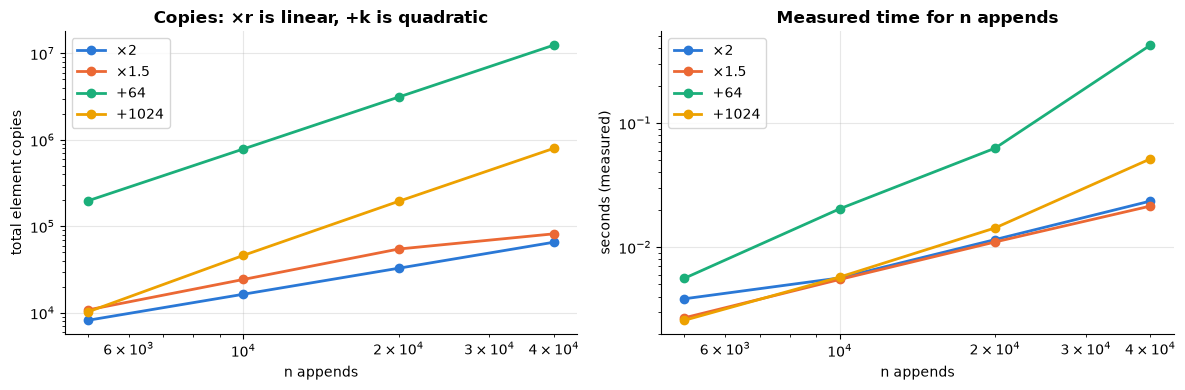

    ×2: copies grow like n^1.00
  ×1.5: copies grow like n^0.99
   +64: copies grow like n^1.99
 +1024: copies grow like n^2.09


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name in policies:
    d = df[df.policy == name]
    axes[0].loglog(d.n, d.copies, "o-", label=name)
    axes[1].loglog(d.n, d.seconds, "o-", label=name)
axes[0].set(xlabel="n appends", ylabel="total element copies", title="Copies: ×r is linear, +k is quadratic")
axes[1].set(xlabel="n appends", ylabel="seconds (measured)", title="Measured time for n appends")
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()

# Growth exponent from the log-log slope between the smallest and largest n
for name in policies:
    d = df[df.policy == name]
    slope = np.polyfit(np.log(d.n), np.log(d.copies), 1)[0]
    print(f"{name:>6}: copies grow like n^{slope:.2f}")

**What just happened?**
- For ×2 the copies per append stay below 2 (1 + 2 + 4 + … + 2ᵏ < 2·2ᵏ < 2n), and for ×1.5 below 3 (n·r/(r−1) = 3n). The exact value wobbles with where n falls between two resizes, but it never grows.
- For +64 and +1024 the copies per append grow in proportion to n. The log-log slope of the total copies is about 1 for the factor policies and about 2 for the constant-increment policies: linear vs quadratic.
- The measured times follow the same pattern. For small n the +k policies can look fine, because the copying is done by fast C code. As n grows, the quadratic term takes over and they fall further and further behind. Exact seconds vary from machine to machine (and with machine load), but the shape does not.

**Trade-off.** A larger factor wastes more memory (up to 50 % of the block is empty after doubling). CPython's `list` over-allocates by roughly 1/8 (about ×1.125) plus a small constant, a memory-friendly choice that is still a constant *factor*, so `append` is still O(1) amortized. You can watch it with `sys.getsizeof`:

In [6]:
lst, last, jumps = [], sys.getsizeof([]), []
for i in range(2000):
    lst.append(i)
    sz = sys.getsizeof(lst)
    if sz != last:                                       # the list reallocated
        jumps.append((len(lst), (sz - sys.getsizeof([])) // 8))   # (length, capacity in pointers)
        last = sz
caps = [c for _, c in jumps]
ratios = [round(caps[i + 1] / caps[i], 3) for i in range(len(caps) - 1)]
print("capacities (pointer slots):", caps[:12], "...", caps[-3:])
print("growth ratios near the end:", ratios[-5:])

capacities (pointer slots): [4, 8, 16, 24, 32, 40, 52, 64, 76, 92, 108, 128] ... [1584, 1788, 2016]
growth ratios near the end: [1.131, 1.129, 1.128, 1.129, 1.128]


**What just happened?** Each capacity is roughly 1.125× the previous one for large lists. A small growth factor means more frequent resizes, but the cost is still a geometric series, so the bound stays O(1) amortized.

> ⚠️ **Common mistake: shrinking too eagerly.** If you halve the array as soon as it is half full, a sequence push, pop, push, pop… at the boundary resizes on *every* operation (Θ(n) each). The standard fix is to halve only when the array is **one quarter** full (CLRS §16.4).

---
## 3. Union-find (disjoint-set union) with rank and path compression

> 💬 **In plain English:** a structure that tracks which items are in the same group, with two tricks that make every question almost instant.

**Intuition.** Groups of friends merge over time and you often ask "are Alice and Bob in the same group?". Each group elects a representative (the root of a tree). `find(x)` walks up parent pointers to the root; `union(x, y)` hangs one root under the other.

Two heuristics make it extremely fast:
- **Union by rank:** hang the shorter tree under the taller one (rank = an upper bound on height). On its own this keeps the height ≤ log₂ n.
- **Path compression:** after `find(x)`, point every node on the path straight at the root.

With both, any sequence of m operations on n elements costs **O(m · α(n))** (Tarjan 1975; CLRS §19.4), where **α(n)** is the **inverse Ackermann function**. It grows so slowly that α(n) ≤ 4 for every n up to far more than the number of atoms in the universe.

**Defining α.** CLRS uses $A_0(j) = j+1$ and $A_k(j) = A_{k-1}^{(j+1)}(j)$ (apply $A_{k-1}$ to j, j+1 times). Then $A_0(1)=2$, $A_1(1)=3$, $A_2(1)=7$, $A_3(1)=2047$, and $A_4(1) \gg 10^{80}$. The inverse is $\alpha(n) = \min\{k : A_k(1) \ge n\}$.

In [7]:
def ackermann_A(k, j, cap=10**100):
    """CLRS's A_k(j). Returns cap + 1 as soon as the value exceeds `cap` (it explodes quickly).
    Closed forms for k <= 2 avoid looping a astronomical number of times."""
    if j > cap:
        return cap + 1
    if k == 0:
        return j + 1                      # A_0(j) = j + 1
    if k == 1:
        return 2 * j + 1                  # A_1(j) = 2j + 1
    if k == 2:                            # A_2(j) = 2^(j+1) (j+1) - 1
        return cap + 1 if j > 340 else 2 ** (j + 1) * (j + 1) - 1
    x = j
    for _ in range(j + 1):                # A_k(j): apply A_{k-1} (j+1) times
        x = ackermann_A(k - 1, x, cap)
        if x > cap:
            return cap + 1
    return x

def alpha(n):
    k = 0
    while ackermann_A(k, 1) < n:
        k += 1
    return k

print("A_k(1) for k = 0..3:", [ackermann_A(k, 1) for k in range(4)], "| A_4(1) > 10^100:", ackermann_A(4, 1) > 10**100)
print(pd.DataFrame({"n": [2, 3, 7, 8, 2047, 2048, 10**6, 10**80],
                    "alpha(n)": [alpha(n) for n in [2, 3, 7, 8, 2047, 2048, 10**6, 10**80]],
                    "log2(n)": [round(math.log2(n), 1) for n in [2, 3, 7, 8, 2047, 2048, 10**6, 10**80]]}).to_string(index=False))

A_k(1) for k = 0..3: [2, 3, 7, 2047] | A_4(1) > 10^100: True
                                                                                n  alpha(n)  log2(n)
                                                                                2         0      1.0
                                                                                3         1      1.6
                                                                                7         2      2.8
                                                                                8         3      3.0
                                                                             2047         3     11.0
                                                                             2048         4     11.0
                                                                          1000000         4     19.9
100000000000000000000000000000000000000000000000000000000000000000000000000000000         4    265.8


In [8]:
class UnionFind:
    """Disjoint-set forest. Options: union by rank, path compression. Counts pointer hops."""
    def __init__(self, n, by_rank=True, compress=True):
        self.parent = list(range(n))
        self.rank = [0] * n
        self.by_rank, self.compress = by_rank, compress
        self.hops = 0                                  # how many parent pointers we followed

    def find(self, x):
        root = x
        while self.parent[root] != root:               # walk up to the root
            root = self.parent[root]
            self.hops += 1
        if self.compress:                              # second pass: point the path at the root
            while self.parent[x] != root:
                self.parent[x], x = root, self.parent[x]
        return root

    def union(self, x, y):
        rx, ry = self.find(x), self.find(y)
        if rx == ry:
            return False
        if self.by_rank:
            if self.rank[rx] < self.rank[ry]:
                rx, ry = ry, rx                        # make rx the taller tree
            if self.rank[rx] == self.rank[ry]:
                self.rank[rx] += 1
        self.parent[ry] = rx                           # hang ry's tree under rx
        return True

def workload(n, seed):
    """n-1 random unions interleaved with 2n random finds (a mixed sequence of ~3n operations)."""
    r = random.Random(seed)
    ops = [("u", r.randrange(n), r.randrange(n)) for _ in range(n - 1)]
    ops += [("f", r.randrange(n), None) for _ in range(2 * n)]
    r.shuffle(ops)
    return ops

def run(uf, ops):
    for kind, a, b in ops:
        uf.union(a, b) if kind == "u" else uf.find(a)
    return uf.hops / len(ops)

# Correctness check against networkx connected components
n = 2000
ops = workload(n, seed=7)
uf = UnionFind(n)
run(uf, ops)
G = nx.Graph(); G.add_nodes_from(range(n)); G.add_edges_from((a, b) for k, a, b in ops if k == "u")
ours = {frozenset(i for i in range(n) if uf.find(i) == r) for r in {uf.find(i) for i in range(n)}}
assert ours == {frozenset(c) for c in nx.connected_components(G)}
print("union-find components match networkx:", len(ours), "components")

union-find components match networkx: 325 components


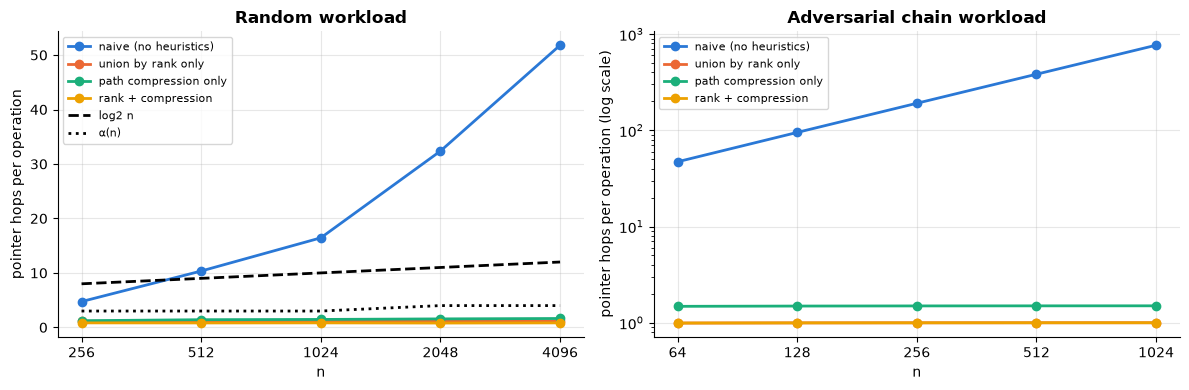

      naive (no heuristics)  union by rank only  path compression only  rank + compression
n                                                                                         
256                    4.74                1.13                   1.22                0.83
512                   10.34                1.13                   1.41                0.81
1024                  16.44                1.15                   1.46                0.83
2048                  32.37                1.14                   1.56                0.79
4096                  51.80                1.18                   1.63                0.82


In [9]:
variants = {"naive (no heuristics)": dict(by_rank=False, compress=False),
            "union by rank only": dict(by_rank=True, compress=False),
            "path compression only": dict(by_rank=False, compress=True),
            "rank + compression": dict(by_rank=True, compress=True)}
ns = [2**k for k in range(8, 13)]
res = {v: [] for v in variants}
for n in ns:
    ops = workload(n, seed=n)
    for v, kw in variants.items():
        res[v].append(run(UnionFind(n, **kw), ops))

# An adversarial sequence for the naive version: union(0,1), union(0,2), ... builds a path
def chain_ops(n):
    return [("u", i, 0) for i in range(1, n)] + [("f", 0, None)] * n

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for v in variants:
    axes[0].plot(ns, res[v], "o-", label=v)
axes[0].plot(ns, np.log2(ns), "k--", label="log2 n")
axes[0].plot(ns, [alpha(n) for n in ns], "k:", label="α(n)")
axes[0].set_xscale("log", base=2); axes[0].set_xticks(ns, [str(v) for v in ns])
axes[0].set(xlabel="n", ylabel="pointer hops per operation", title="Random workload")
axes[0].legend(fontsize=8)
chain_ns = [2**k for k in range(6, 11)]
for v, kw in variants.items():
    axes[1].plot(chain_ns, [run(UnionFind(m, **kw), chain_ops(m)) for m in chain_ns], "o-", label=v)
axes[1].set_xscale("log", base=2); axes[1].set_xticks(chain_ns, [str(v) for v in chain_ns]); axes[1].set_yscale("log")
axes[1].set(xlabel="n", ylabel="pointer hops per operation (log scale)", title="Adversarial chain workload")
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(pd.DataFrame(res, index=ns).round(2).rename_axis("n"))

**What just happened?**
- On the random workload the **naive** version already degrades: its hops per operation grow steadily with n (look at the first column of the table), because blindly hanging one root under the other builds tall trees. The three improved variants stay around 1–2 hops per operation, and rank + compression is the lowest and flat (below the α(n) curve here, because most finds hit very short paths).
- The **adversarial chain** (`union(i, 0)` for i = 1, 2, …, without rank) builds a path of length n, so every `find(0)` walks the whole path. The naive cost per operation grows linearly with n (a straight line of slope 1 on the log-log plot). Union by rank stops the tree from getting tall (here it builds a star, so its line is hidden under the rank + compression line at about 1 hop), and path compression alone flattens the path after the first walk.

**Complexity summary**

| Variant | find / union (worst case per op) | m operations |
|---|---|---|
| naive | O(n) | O(m·n) |
| union by rank (or by size) | O(log n) | O(m log n) |
| path compression only | O(log n) amortized | O(m log n) (Tarjan & van Leeuwen 1984: Θ(m log_{1+m/n} n)) |
| rank + compression | O(α(n)) amortized | **O(m α(n))**, and this is optimal |

Space: O(n) for `parent` and `rank`.

> 🎓 **Exam / interview tip:** union-find is the engine of **Kruskal's MST**, cycle detection in undirected graphs, "number of islands / provinces" interview questions, and connected-component labelling in images. Say "near-constant amortized, O(α(n))" and mention *both* heuristics.

---
## 4. Randomized algorithms: Las Vegas vs Monte Carlo

> 💬 **In plain English:** algorithms that flip coins come in two kinds: always right but with random speed, or always fast but rarely wrong.

A **randomized algorithm** makes random choices while it runs. The randomness is *inside the algorithm*, not in the input, so the guarantees hold for **every** input. The probability is over the algorithm's coin flips only.

| Type | Answer | Running time | Classic examples |
|---|---|---|---|
| **Las Vegas** | **always correct** | random; we bound the **expected** time | randomized quicksort, quickselect, skip lists, treaps |
| **Monte Carlo** | correct **with high probability** | bounded (deterministic) | Miller–Rabin, Karger's min-cut, Freivalds' check, Bloom filters |

A Monte Carlo algorithm has **one-sided error** if it can only be wrong in one direction (Miller–Rabin never calls a prime "composite") and **two-sided error** otherwise. Complexity classes: ZPP (Las Vegas in expected polynomial time), RP (one-sided Monte Carlo), BPP (two-sided Monte Carlo).

You can convert in both directions:
- **Las Vegas → Monte Carlo:** stop after a time budget and output "don't know" (or a guess). By Markov's inequality, stopping at 2 × the expected time fails with probability ≤ ½.
- **Monte Carlo → Las Vegas:** possible if you can *check* an answer quickly: repeat until the check passes.

**Expected vs worst-case time.** For randomized quicksort, the worst case is still Θ(n²) (if every pivot is unlucky), but the *expected* time is Θ(n log n) on **every** input, and the bad case has vanishingly small probability. Contrast this with average-case analysis of a deterministic quicksort, which assumes the *input* is random: an adversary who knows your pivot rule can always feed you the bad input.

Toy example: half the cells of an array contain `"a"`. Find any `"a"`.

Las Vegas: mean probes = 2.009 (theory: 1/p = 2), max seen = 16
Monte Carlo with k= 1 probes: failure rate = 0.5001 (theory 2^-k = 0.5000)
Monte Carlo with k= 3 probes: failure rate = 0.1230 (theory 2^-k = 0.1250)
Monte Carlo with k= 5 probes: failure rate = 0.0319 (theory 2^-k = 0.0312)
Monte Carlo with k=10 probes: failure rate = 0.0013 (theory 2^-k = 0.0010)


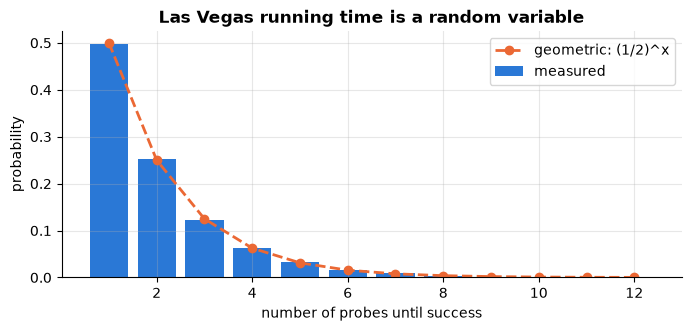

In [10]:
def las_vegas_find_a(arr, rng):
    """Probe random positions until we hit an 'a'. Always correct; time is random."""
    probes = 0
    while True:
        i = rng.randrange(len(arr)); probes += 1
        if arr[i] == "a":
            return i, probes

def monte_carlo_find_a(arr, rng, k):
    """At most k probes. Time is bounded; may fail with probability 2**-k."""
    for _ in range(k):
        i = rng.randrange(len(arr))
        if arr[i] == "a":
            return i
    return None

rng = random.Random(0)
arr = ["a"] * 500 + ["b"] * 500
rng.shuffle(arr)
probes = [las_vegas_find_a(arr, rng)[1] for _ in range(20000)]
print(f"Las Vegas: mean probes = {np.mean(probes):.3f} (theory: 1/p = 2), max seen = {max(probes)}")
for k in [1, 3, 5, 10]:
    fails = sum(monte_carlo_find_a(arr, rng, k) is None for _ in range(20000)) / 20000
    print(f"Monte Carlo with k={k:2d} probes: failure rate = {fails:.4f} (theory 2^-k = {2**-k:.4f})")

counts = Counter(probes)
fig, ax = plt.subplots(figsize=(8, 3.2))
xs = range(1, 13)
ax.bar(xs, [counts[x] / len(probes) for x in xs], color=PALETTE[0], label="measured")
ax.plot(xs, [0.5**x for x in xs], "o--", color=PALETTE[1], label="geometric: (1/2)^x")
ax.set(xlabel="number of probes until success", ylabel="probability", title="Las Vegas running time is a random variable")
ax.legend(); plt.show()

**What just happened?** The Las Vegas search always returns a correct index. Its number of probes follows a geometric distribution with mean 2. It is unbounded in the worst case, but needing more than 20 probes has probability 2⁻²⁰ ≈ 10⁻⁶. The Monte Carlo version caps the work at k probes and pays with a failure probability of 2⁻ᵏ, which matches the measurements.

---
## 5. Randomized quicksort and quickselect

> 💬 **In plain English:** pick the splitting element at random and quicksort (and finding the median) is fast on every input.

**Randomized quicksort** picks the pivot uniformly at random. Elements z_i and z_j (the i-th and j-th smallest) are compared **iff** one of them is the first pivot chosen among z_i, …, z_j, which has probability 2/(j − i + 1). By linearity of expectation:

$$E[\text{comparisons}] = \sum_{i<j} \frac{2}{j-i+1} = 2(n+1)H_n - 4n \approx 2n\ln n \approx 1.39\, n\log_2 n ,$$

where $H_n = 1 + \tfrac12 + \dots + \tfrac1n$ is the harmonic number (CLRS §7.4).

**Quickselect** (Hoare's FIND) returns the k-th smallest element. It partitions like quicksort but recurses into **one side only**. Expected comparisons are at most 4n, so the time is **O(n) expected**. For the median the expected count tends to 2(1 + ln 2)·n ≈ 3.39n. The worst case is still Θ(n²); the deterministic "median of medians" algorithm (CLRS §9.3) gets O(n) worst case but with a larger constant.

Worked example of one partition step with pivot 5:

```
[7, 2, 9, 5, 1, 8, 3]  → less = [2, 1, 3]   pivot = [5]   greater = [7, 9, 8]
                          6 comparisons (every other element is compared with the pivot once)
k = 4 (the 4th smallest)? |less| = 3, so the answer is the pivot itself: 5.
```

In [11]:
def quicksort(a, rng, pivot="random"):
    """Return (sorted list, number of element-vs-pivot comparisons)."""
    if len(a) <= 1:
        return list(a), 0
    p = a[rng.randrange(len(a))] if pivot == "random" else a[0]
    less = [x for x in a if x < p]
    equal = [x for x in a if x == p]
    greater = [x for x in a if x > p]
    left, cl = quicksort(less, rng, pivot)
    right, cr = quicksort(greater, rng, pivot)
    return left + equal + right, (len(a) - 1) + cl + cr      # each non-pivot compared with p once

def quickselect(a, k, rng):
    """k-th smallest (k = 0 is the minimum). Returns (value, comparisons). Iterative: no deep recursion."""
    comps = 0
    while True:
        if len(a) == 1:
            return a[0], comps
        p = a[rng.randrange(len(a))]
        less = [x for x in a if x < p]
        equal = [x for x in a if x == p]
        comps += len(a) - 1
        if k < len(less):
            a = less                                   # answer is on the left
        elif k < len(less) + len(equal):
            return p, comps                            # the pivot is the answer
        else:
            k -= len(less) + len(equal)                # answer is on the right
            a = [x for x in a if x > p]

rng = random.Random(3)
for trial in range(200):                               # correctness against sorted / numpy
    a = [rng.randint(-50, 50) for _ in range(rng.randint(1, 60))]
    assert quicksort(a, rng)[0] == sorted(a)
    k = rng.randrange(len(a))
    assert quickselect(a, k, rng)[0] == sorted(a)[k] == np.partition(np.array(a), k)[k]
print("quicksort and quickselect agree with sorted() and np.partition on 200 random inputs")

n = 1000
H = sum(1 / i for i in range(1, n + 1))
expected_qs = 2 * (n + 1) * H - 4 * n
data = rng.sample(range(10**6), n)                     # distinct keys
qs_counts = [quicksort(data, rng)[1] for _ in range(300)]
sel_counts = [quickselect(data, n // 2, rng)[1] for _ in range(300)]
_, det_sorted = quicksort(sorted(data)[:500], rng, pivot="first")   # first-element pivot on sorted input
print(f"randomized quicksort, n={n}: mean comparisons {np.mean(qs_counts):.0f} vs formula {expected_qs:.0f}")
print(f"   min {min(qs_counts)}, max {max(qs_counts)}  (n log2 n = {n * math.log2(n):.0f})")
print(f"quickselect for the median: mean {np.mean(sel_counts):.0f} = {np.mean(sel_counts) / n:.2f}·n (theory ≈ 3.39n, bound 4n)")
print(f"deterministic first-pivot quicksort on SORTED input, n=500: {det_sorted} comparisons = n(n-1)/2 = {500 * 499 // 2}")

quicksort and quickselect agree with sorted() and np.partition on 200 random inputs


randomized quicksort, n=1000: mean comparisons 11036 vs formula 10986
   min 9887, max 14170  (n log2 n = 9966)
quickselect for the median: mean 3273 = 3.27·n (theory ≈ 3.39n, bound 4n)
deterministic first-pivot quicksort on SORTED input, n=500: 124750 comparisons = n(n-1)/2 = 124750


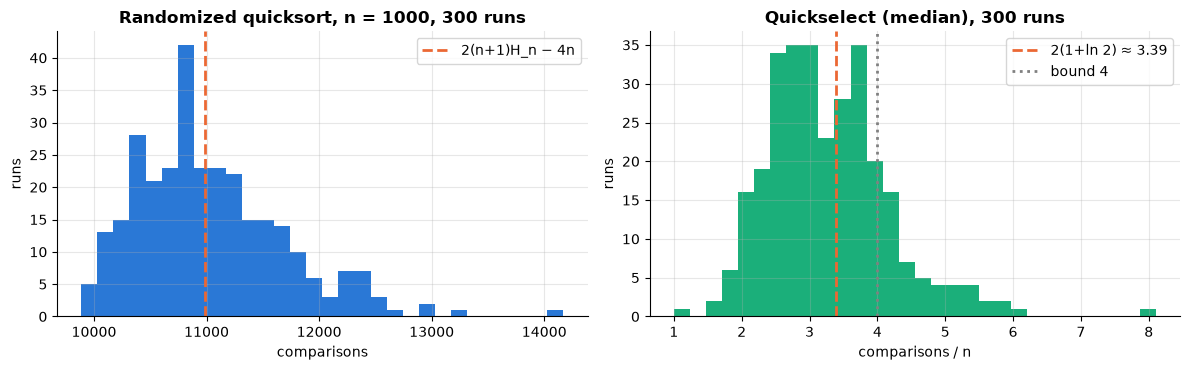

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(qs_counts, bins=30, color=PALETTE[0])
axes[0].axvline(expected_qs, color=PALETTE[1], ls="--", label="2(n+1)H_n − 4n")
axes[0].set(xlabel="comparisons", ylabel="runs", title=f"Randomized quicksort, n = {n}, 300 runs"); axes[0].legend()
axes[1].hist(np.array(sel_counts) / n, bins=30, color=PALETTE[2])
axes[1].axvline(2 * (1 + math.log(2)), color=PALETTE[1], ls="--", label="2(1+ln 2) ≈ 3.39")
axes[1].axvline(4, color="gray", ls=":", label="bound 4")
axes[1].set(xlabel="comparisons / n", ylabel="runs", title="Quickselect (median), 300 runs"); axes[1].legend()
plt.tight_layout(); plt.show()

**What just happened?** The mean number of quicksort comparisons is close to the exact formula 2(n+1)H_n − 4n, and the distribution is **tightly concentrated**: even the worst of 300 runs is far from the n(n−1)/2 ≈ 500,000 comparisons of the worst case. Quickselect's comparisons cluster around 3.3n, close to the theoretical 3.39n; individual runs scatter around it (4n bounds the *expectation*, not every single run). The deterministic first-element pivot on already-sorted input hits the worst case exactly: n(n−1)/2 comparisons.

| Algorithm | Best | Expected (any input) | Worst | Extra space |
|---|---|---|---|---|
| randomized quicksort | Θ(n log n) | Θ(n log n), ≈ 1.39 n log₂ n compares | Θ(n²) (probability → 0) | O(log n) expected stack (in-place version) |
| quickselect | Θ(n) | Θ(n), ≤ 4n compares | Θ(n²) | O(1) iterative, in place |
| median of medians | Θ(n) | Θ(n) | **Θ(n)** | O(log n) |

> ⚠️ **Common mistake:** "random pivot makes quicksort O(n log n) worst case". No: the worst case is still Θ(n²). What changes is that *no input* is bad; only unlucky coin flips are, and they are extremely unlikely.

---
## 6. Universal hashing

> 💬 **In plain English:** choose the hash function at random when the table is created, so no attacker can force all keys into one slot.

**Problem.** A hash table with a fixed hash function has a fixed set of bad inputs. If an attacker sends keys that all land in one bucket, every lookup becomes O(n). This is a real denial-of-service attack ("hash flooding", 2011–2012 against web frameworks). It is why Python randomizes `str`/`bytes` hashing (SipHash with a per-process random key; see `PYTHONHASHSEED`). Python's `int` hash, however, is simply the number itself (modulo 2⁶¹ − 1), so it is easy to attack.

**Definition (Carter & Wegman, 1979).** A family 𝓗 of functions U → {0, …, m−1} is **universal** if, for every pair of distinct keys x ≠ y,

$$\Pr_{h \in \mathcal H}[h(x) = h(y)] \le \frac{1}{m}.$$

**Construction.** Pick a prime p larger than any key. For a ∈ {1, …, p−1} and b ∈ {0, …, p−1}:

$$h_{a,b}(x) = ((a x + b) \bmod p) \bmod m .$$

This family is universal (CLRS Theorem 11.5). Choosing h at random **when the table is created** means no fixed input is bad for most choices. With chaining, the expected length of the chain a lookup scans is ≤ 1 + n/m = 1 + α, where α = n/m is the **load factor**.

collision rate per fixed pair over 3000 random h: mean 0.0101, max 0.0143, bound 1/m = 0.0103
adversarial keys, n = 2000, m = 97 (expected load n/m = 20.6):
   Python hash % m : buckets used =   1, largest bucket = 2000
   universal h     : buckets used =  97, largest bucket = 22


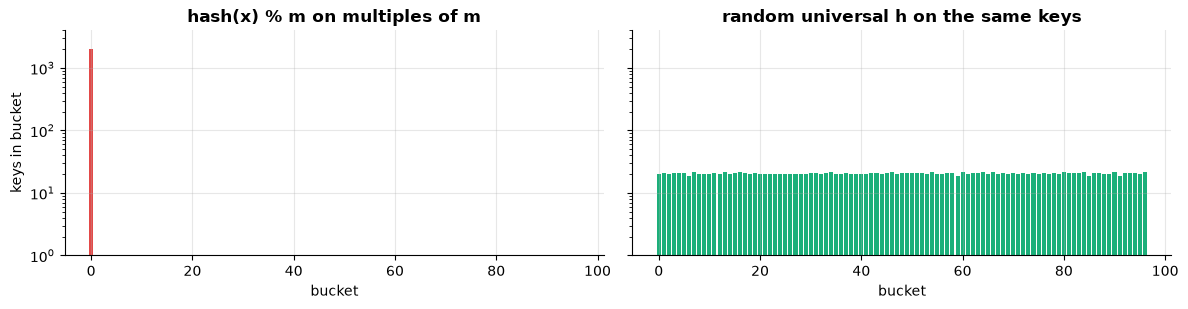

In [13]:
P = (1 << 61) - 1                                # a Mersenne prime, bigger than our keys

def random_universal_hash(m, rng):
    a = rng.randrange(1, P)
    b = rng.randrange(0, P)
    return lambda x: ((a * x + b) % P) % m

m = 97                                           # number of buckets
rng = random.Random(5)
pairs = [(rng.randrange(10**12), rng.randrange(10**12)) for _ in range(30)]
pairs = [(x, y) for x, y in pairs if x != y]
trials = 3000
hs = [random_universal_hash(m, rng) for _ in range(trials)]
rates = [sum(h(x) == h(y) for h in hs) / trials for x, y in pairs]
print(f"collision rate per fixed pair over {trials} random h: mean {np.mean(rates):.4f}, max {max(rates):.4f}, bound 1/m = {1/m:.4f}")

# The adversary: keys that are multiples of m all hit bucket 0 with Python's hash(x) % m
n_keys = 2000
evil_keys = [i * m for i in range(n_keys)]
python_loads = Counter(hash(k) % m for k in evil_keys)
h = random_universal_hash(m, rng)
universal_loads = Counter(h(k) for k in evil_keys)
print(f"adversarial keys, n = {n_keys}, m = {m} (expected load n/m = {n_keys / m:.1f}):")
print(f"   Python hash % m : buckets used = {len(python_loads):3d}, largest bucket = {max(python_loads.values())}")
print(f"   universal h     : buckets used = {len(universal_loads):3d}, largest bucket = {max(universal_loads.values())}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2), sharey=True)
axes[0].bar(range(m), [python_loads[i] for i in range(m)], color=PALETTE[7])
axes[0].set(title="hash(x) % m on multiples of m", xlabel="bucket", ylabel="keys in bucket")
axes[1].bar(range(m), [universal_loads[i] for i in range(m)], color=PALETTE[2])
axes[1].set(title="random universal h on the same keys", xlabel="bucket")
axes[1].set_yscale("log"); axes[0].set_yscale("log"); axes[0].set_ylim(1, 4000)
plt.tight_layout(); plt.show()

**What just happened?** Over random choices of h, every fixed pair collides with probability about 1/97 ≈ 0.0103, as the theorem promises (sampling noise makes some pairs slightly above or below). The adversarial keys (multiples of 97) all land in **one bucket** under `hash(x) % m`, turning the table into a linked list. The randomly chosen universal function spreads the same keys almost evenly, with the largest bucket only a little above the average load of about 20.6.

> 🎓 **Exam / interview tip:** "universal" bounds collisions of **pairs**. Stronger notions exist: **k-wise independent** families (needed for linear probing and for sketches like Count-Min, see the next batch of notebooks), and **perfect hashing** (FKS: two levels of universal hashing give O(1) *worst-case* lookups for a static set, with O(n) space).

---
## 7. Skip lists

> 💬 **In plain English:** a sorted linked list with random 'express lanes' on top, so searches can skip ahead.

**Intuition.** On a long train line, an express train stops only at big stations. To reach a small station you take the express as far as possible, then switch to the local train. A **skip list** (Pugh, 1990) is a sorted linked list with extra "express lanes" on top.

**Definition.** Every element is in level 0 (a sorted linked list). Each element is promoted to the next level with probability p (usually ½), independently, by **coin flips**. Search starts at the top level of a sentinel head, moves right while the next key is smaller than the target, and drops down a level when it cannot move right.

```
level 3: head ─────────────────────────────► 50 ─────────────────► None
level 2: head ──────────► 17 ──────────────► 50 ─────────────────► None
level 1: head ──► 5 ────► 17 ──────► 31 ───► 50 ──────► 77 ──────► None
level 0: head ──► 5 ► 9 ► 17 ► 21 ► 31 ► 40 ► 50 ► 63 ► 77 ► 88 ──► None
search(40): head(L3)→50? too big, down; L2: →17, →50? too big, down;
            L1: →31, →50? too big, down; L0: →40 ✓
```

Expected facts (p = ½): the number of levels is about log₂ n; a search, insert or delete takes **O(log n) expected** time; the expected total number of pointers is n(1 + ½ + ¼ + …) = **2n**, so the space is O(n). It is a **Las Vegas** structure: always correct, and only the running time is random. Real systems use skip lists: Redis sorted sets, LevelDB/RocksDB memtables, and Java's `ConcurrentSkipListMap` (they are easier to make concurrent than balanced trees).

In [14]:
class SkipNode:
    __slots__ = ("key", "next")
    def __init__(self, key, level):
        self.key = key
        self.next = [None] * level          # next[i] = successor at level i

class SkipList:
    MAX_LEVEL = 32

    def __init__(self, p=0.5, seed=0):
        self.p = p
        self.rng = random.Random(seed)
        self.head = SkipNode(None, self.MAX_LEVEL)   # sentinel with all levels
        self.level = 1                               # levels currently in use
        self.size = 0

    def _random_level(self):
        lvl = 1
        while self.rng.random() < self.p and lvl < self.MAX_LEVEL:
            lvl += 1                                 # keep flipping coins: promote with probability p
        return lvl

    def _find_update(self, key):
        """For each level, the last node with node.key < key (where we would splice in)."""
        update = [None] * self.MAX_LEVEL
        x = self.head
        for i in range(self.level - 1, -1, -1):      # from the top level down
            while x.next[i] is not None and x.next[i].key < key:
                x = x.next[i]                        # move right along level i
            update[i] = x
        return update

    def search(self, key):
        x = self._find_update(key)[0].next[0]
        return x is not None and x.key == key

    def insert(self, key):
        update = self._find_update(key)
        nxt = update[0].next[0]
        if nxt is not None and nxt.key == key:
            return False                             # no duplicates
        lvl = self._random_level()
        if lvl > self.level:
            for i in range(self.level, lvl):
                update[i] = self.head                # new levels start at the head
            self.level = lvl
        node = SkipNode(key, lvl)
        for i in range(lvl):                         # splice the node into each of its levels
            node.next[i] = update[i].next[i]
            update[i].next[i] = node
        self.size += 1
        return True

    def delete(self, key):
        update = self._find_update(key)
        x = update[0].next[0]
        if x is None or x.key != key:
            return False
        for i in range(len(x.next)):                 # unlink from every level it appears in
            if update[i].next[i] is x:
                update[i].next[i] = x.next[i]
        while self.level > 1 and self.head.next[self.level - 1] is None:
            self.level -= 1                          # drop empty top levels
        self.size -= 1
        return True

    def keys(self):
        x, out = self.head.next[0], []
        while x is not None:
            out.append(x.key); x = x.next[0]
        return out

# Randomized differential test against a Python set
rng = random.Random(11)
sl, ref = SkipList(seed=1), set()
for _ in range(20000):
    k, op = rng.randrange(500), rng.random()
    if op < 0.5:
        assert sl.insert(k) == (k not in ref); ref.add(k)
    elif op < 0.8:
        assert sl.delete(k) == (k in ref); ref.discard(k)
    else:
        assert sl.search(k) == (k in ref)
assert sl.keys() == sorted(ref) and sl.size == len(ref)
print("skip list passed 20,000 random insert/delete/search operations against a set")

big = SkipList(seed=2)
for k in random.Random(3).sample(range(10**7), 50_000):
    big.insert(k)
per_level = Counter()
x = big.head.next[0]
while x is not None:
    for i in range(len(x.next)): per_level[i] += 1
    x = x.next[0]
print(f"n = {big.size}: levels = {big.level} (log2 n = {math.log2(big.size):.1f}), "
      f"total pointers = {sum(per_level.values())} ≈ 2n = {2 * big.size}")
print("nodes per level (expected n/2^i):", [per_level[i] for i in range(8)], "...")

skip list passed 20,000 random insert/delete/search operations against a set


n = 50000: levels = 18 (log2 n = 15.6), total pointers = 99837 ≈ 2n = 100000
nodes per level (expected n/2^i): [50000, 24909, 12469, 6304, 3129, 1530, 724, 355] ...


**What just happened?** The skip list passed a randomized **differential test**: 20,000 random operations, each checked against a Python `set`. This is a powerful habit for testing data structures. With 50,000 keys it built about log₂ n ≈ 15.6 levels (a few more from lucky coin flips), each level holds about half the nodes of the one below, and the total number of forward pointers is very close to 2n.

---
## 8. Treaps

> 💬 **In plain English:** a search tree that stays balanced because every key gets a random priority.

**Definition.** A **treap** (tree + heap; Aragon & Seidel, 1989) stores (key, priority) pairs. It is a **binary search tree by key** and a **max-heap by priority**. Each priority is chosen **at random** at insertion time.

**Why it is balanced.** For distinct keys and priorities, the treap is exactly the BST you would get by inserting the keys in decreasing order of priority. Random priorities therefore give a **random BST**, whose expected depth is about 2 ln n ≈ 1.39 log₂ n. So search, insert and delete take **O(log n) expected** time, whatever order the keys arrive in.

- **insert:** do a normal BST insert at a leaf, then **rotate it up** while its priority beats its parent's.
- **delete:** rotate the node **down** (always lifting the child with the larger priority) until it is a leaf, then cut it off.

```
rotate right at y:            y              x
                             / \            / \
                            x   C   ──►    A   y
                           / \                / \
                          A   B              B   C     (BST order A < x < B < y < C is kept)
```

In [15]:
class TreapNode:
    __slots__ = ("key", "prio", "left", "right")
    def __init__(self, key, prio):
        self.key, self.prio, self.left, self.right = key, prio, None, None

def rotate_right(y):
    x = y.left
    y.left, x.right = x.right, y
    return x

def rotate_left(x):
    y = x.right
    x.right, y.left = y.left, x
    return y

class Treap:
    def __init__(self, seed=0):
        self.root = None
        self.rng = random.Random(seed)
        self.size = 0

    def _insert(self, node, key):
        if node is None:
            self.size += 1
            return TreapNode(key, self.rng.random())        # random priority
        if key < node.key:
            node.left = self._insert(node.left, key)
            if node.left.prio > node.prio:                   # heap property broken: rotate up
                node = rotate_right(node)
        elif key > node.key:
            node.right = self._insert(node.right, key)
            if node.right.prio > node.prio:
                node = rotate_left(node)
        return node                                          # equal key: already present

    def insert(self, key):
        self.root = self._insert(self.root, key)

    def _delete(self, node, key):
        if node is None:
            return None
        if key < node.key:
            node.left = self._delete(node.left, key)
        elif key > node.key:
            node.right = self._delete(node.right, key)
        else:                                                # found it: rotate it down to a leaf
            if node.left is None or node.right is None:
                self.size -= 1
                return node.left or node.right
            if node.left.prio > node.right.prio:
                node = rotate_right(node)
                node.right = self._delete(node.right, key)
            else:
                node = rotate_left(node)
                node.left = self._delete(node.left, key)
        return node

    def delete(self, key):
        self.root = self._delete(self.root, key)

    def search(self, key):
        x = self.root
        while x is not None and x.key != key:
            x = x.left if key < x.key else x.right
        return x is not None

    def height(self):
        def h(x): return 0 if x is None else 1 + max(h(x.left), h(x.right))
        return h(self.root)

    def check(self):
        """Verify the BST order and the heap order; return keys in order."""
        out = []
        def walk(x, lo, hi):
            if x is None: return
            assert lo < x.key < hi
            for c in (x.left, x.right):
                assert c is None or c.prio <= x.prio
            walk(x.left, lo, x.key); out.append(x.key); walk(x.right, x.key, hi)
        walk(self.root, -math.inf, math.inf)
        return out

rng = random.Random(12)
tr, ref = Treap(seed=4), set()
for _ in range(20000):
    k, op = rng.randrange(500), rng.random()
    if op < 0.5:   tr.insert(k); ref.add(k)
    elif op < 0.8: tr.delete(k); ref.discard(k)
    else:          assert tr.search(k) == (k in ref)
assert tr.check() == sorted(ref) and tr.size == len(ref)
print("treap passed 20,000 random operations; BST and heap invariants hold")

# The killer test for a plain BST: sorted insertion order
n = 20000
t = Treap(seed=5)
for k in range(n):                     # sorted input would make a plain BST a path of height n
    t.insert(k)
print(f"treap built from SORTED keys 0..{n-1}: height {t.height()} "
      f"(log2 n = {math.log2(n):.1f}, 2 ln n = {2 * math.log(n):.1f}); a plain BST would have height {n}")

treap passed 20,000 random operations; BST and heap invariants hold


treap built from SORTED keys 0..19999: height 32 (log2 n = 14.3, 2 ln n = 19.8); a plain BST would have height 20000


**What just happened?** The treap passed the same kind of differential test as the skip list, and its two invariants (BST order on keys, heap order on priorities) were checked after the run. The striking result: inserting **sorted** keys, the worst case for a plain BST, still gives a height of only a few times log₂ n, because the shape depends only on the random priorities.

### Benchmark: skip list and treap vs `bisect` on a sorted Python list

A sorted list with `bisect.insort` finds the position in O(log n), but **inserting shifts every later element**, so an insert is O(n) (done by a fast C `memmove`). Skip lists and treaps insert in O(log n) expected, but each step is slow interpreted Python. Which wins depends on n.

In [16]:
def time_inserts(build, insert, n, batch=2000, seed=0):
    """Build a structure holding n random keys, then time `batch` further inserts (seconds per insert)."""
    r = random.Random(seed)
    keys = r.sample(range(10**9), n + batch)
    s = build(keys[:n])
    t0 = time.perf_counter()
    for k in keys[n:]:
        insert(s, k)
    return (time.perf_counter() - t0) / batch

def build_by_inserting(cls):
    def build(keys):
        s = cls(seed=1)
        for k in keys:
            s.insert(k)
        return s
    return build

bench_n = [1_000, 10_000, 100_000, 400_000]
rows = []
for n in bench_n:
    rows.append({"n": n,
                 "bisect.insort (list)": time_inserts(sorted, bisect.insort, n),   # sorted() builds the list fast
                 "skip list": time_inserts(build_by_inserting(SkipList), SkipList.insert, n) if n <= 100_000 else np.nan,
                 "treap": time_inserts(build_by_inserting(Treap), Treap.insert, n) if n <= 100_000 else np.nan})
bench = pd.DataFrame(rows).set_index("n")
print((bench * 1e6).round(2).rename(columns=lambda c: c + " µs/insert"))

        bisect.insort (list) µs/insert  skip list µs/insert  treap µs/insert
n                                                                           
1000                              1.52                 8.65             6.99
10000                             6.36                11.29             8.91
100000                           56.72                13.38            11.65
400000                          117.84                  NaN              NaN


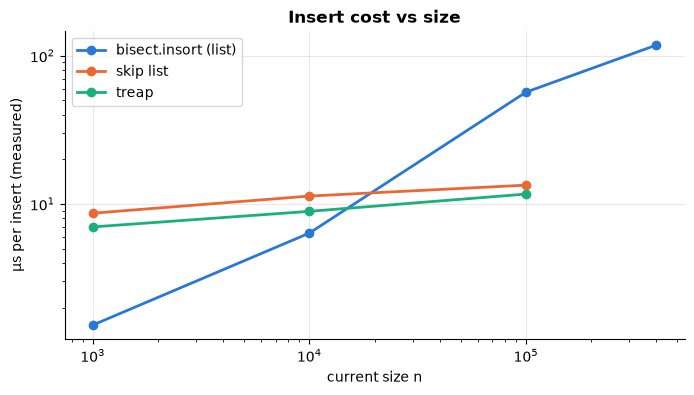

bisect.insort per-insert time grew 77.4x from n = 1,000 to n = 400,000
n =   1,000: fastest insert = bisect.insort (list)
n =  10,000: fastest insert = bisect.insort (list)
n = 100,000: fastest insert = treap


In [17]:
fig, ax = plt.subplots(figsize=(8, 4))
for col in bench.columns:
    d = bench[col].dropna()
    ax.loglog(d.index, d.values * 1e6, "o-", label=col)
ax.set(xlabel="current size n", ylabel="µs per insert (measured)", title="Insert cost vs size")
ax.legend(); plt.show()
ratio = bench["bisect.insort (list)"].iloc[-1] / bench["bisect.insort (list)"].iloc[0]
print(f"bisect.insort per-insert time grew {ratio:.1f}x from n = {bench_n[0]:,} to n = {bench_n[-1]:,}")
for n_, row in bench.iterrows():
    if not np.isnan(row["skip list"]):
        print(f"n = {n_:>7,}: fastest insert = {row.idxmin()}")

**What just happened?** Read the numbers in your own output rather than trusting fixed values; they depend on your machine and its current load.
- For small n, `bisect.insort` is **faster per insert** than our pure-Python skip list and treap, because shifting a few thousand pointers with C's `memmove` is cheaper than a dozen interpreted Python steps.
- Its cost grows roughly linearly with n (the O(n) shift), while the skip list and treap curves grow only slowly (O(log n), plus more cache misses as the structure grows). So the curves **cross**: somewhere between n ≈ 10³ and 10⁵, depending on the machine and its load, after which the O(log n) structures win even in pure Python. The cell above prints the fastest structure at each size on your run.
- Lesson: **asymptotics decide the winner only for large enough n**, and constant factors (C vs Python) matter a lot in practice. A skip list or balanced tree written in C (Redis, RocksDB, `sortedcontainers`) also wins on huge sizes, supports concurrent access and avoids giant memory moves. For a Python program with a few hundred thousand keys, a sorted list + `bisect` is often the pragmatic choice.

| Structure | search | insert / delete | space | type of guarantee |
|---|---|---|---|---|
| sorted array + bisect | O(log n) | O(n) (shift) | n | worst case |
| skip list (p = ½) | O(log n) expected | O(log n) expected | ≈ 2n pointers expected | randomized (Las Vegas) |
| treap | O(log n) expected | O(log n) expected | n nodes | randomized (Las Vegas) |
| red-black / AVL tree | O(log n) | O(log n) | n nodes | worst case, deterministic |

---
## 9. Miller–Rabin primality testing

> 💬 **In plain English:** a fast test that a big number is prime, which can be wrong only with a chance you can make as small as you like.

Checking whether a 300-digit number is prime by trial division would take longer than the age of the universe. RSA key generation needs this every day, and it uses a **Monte Carlo** test.

**Fermat test.** If n is prime, then $a^{n-1} \equiv 1 \pmod n$ for every a not divisible by n (Fermat's little theorem). If some a violates this, n is certainly composite. But **Carmichael numbers** (561 = 3·11·17, 1105, 1729, …) satisfy the congruence for *every* a coprime to n, so the Fermat test is fooled.

**Miller–Rabin.** Write $n - 1 = 2^s d$ with d odd. For a random base a, compute $x = a^d \bmod n$ and square it up to s − 1 times. If n is prime, the sequence either starts at 1 or reaches −1 (≡ n − 1), because the only square roots of 1 modulo a prime are ±1. Otherwise a is a **witness** that n is composite. For odd composite n, at most **¼** of the bases are "strong liars" (Rabin 1980). So k independent rounds give error probability **≤ 4⁻ᵏ** (one-sided: a prime is never rejected). Each round costs O(log n) modular multiplications, so the test runs in O(k log³ n) bit operations with schoolbook multiplication.

Testing the fixed bases {2, 3, 5, …, 37} (the first 12 primes) is a **deterministic** test for every n < 3.3 × 10²⁴, which covers all 64-bit integers.

In [18]:
def sieve(limit):
    """Sieve of Eratosthenes: is_prime[i] for 0 <= i <= limit."""
    is_p = [True] * (limit + 1); is_p[0] = is_p[1] = False
    for i in range(2, int(limit ** 0.5) + 1):
        if is_p[i]:
            is_p[i * i::i] = [False] * len(range(i * i, limit + 1, i))
    return is_p

def trial_factor(n):
    """Trial-division factorisation (fine for small n)."""
    out, d = [], 2
    while d * d <= n:
        while n % d == 0:
            out.append(d); n //= d
        d += 1
    return out + ([n] if n > 1 else [])

def fermat_test(n, a):
    return pow(a, n - 1, n) == 1                 # True means "probably prime"

def miller_rabin_round(n, a):
    """True if base a does NOT prove n composite (n odd, n > 3)."""
    d, s = n - 1, 0
    while d % 2 == 0:
        d //= 2; s += 1                          # n - 1 = 2^s * d with d odd
    x = pow(a, d, n)                             # fast modular exponentiation
    if x == 1 or x == n - 1:
        return True
    for _ in range(s - 1):
        x = x * x % n                            # keep squaring
        if x == n - 1:
            return True
    return False                                 # a is a witness: n is composite

def is_probable_prime(n, k=20, rng=random):
    if n < 2: return False
    for p in (2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37):
        if n % p == 0: return n == p
    return all(miller_rabin_round(n, rng.randrange(2, n - 1)) for _ in range(k))

def is_prime_deterministic_64(n):
    if n < 2: return False
    small = (2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37)
    for p in small:
        if n % p == 0: return n == p
    return all(miller_rabin_round(n, a) for a in small)

LIMIT = 100_000
truth = sieve(LIMIT)
rng = random.Random(9)
assert all(is_probable_prime(i, k=8, rng=rng) == truth[i] for i in range(LIMIT + 1))
assert all(is_prime_deterministic_64(i) == truth[i] for i in range(LIMIT + 1))
print(f"Miller-Rabin agrees with the sieve on every n <= {LIMIT:,}")

carmichael = [561, 1105, 1729, 2465, 2821, 6601, 8911]
rows = []
for n in carmichael:
    coprime = [a for a in range(2, n - 1) if math.gcd(a, n) == 1]
    fermat_liars = sum(fermat_test(n, a) for a in coprime)
    strong_liars = sum(miller_rabin_round(n, a) for a in range(2, n - 1))
    rows.append({"n": n, "Fermat liars among coprime a": f"{fermat_liars}/{len(coprime)}",
                 "strong liars (all a in 2..n-2)": strong_liars,
                 "fraction strong liars": round(strong_liars / (n - 3), 4)})
print(pd.DataFrame(rows).to_string(index=False))

big_prime = 2**127 - 1                          # a Mersenne prime
# Which odd composite below 1000 has the largest fraction of strong liars?
worst = max((sum(miller_rabin_round(n, a) for a in range(2, n - 1)) / (n - 3), n)
            for n in range(15, 1000, 2) if not truth[n])
print(f"largest strong-liar fraction among odd composites 15..999: {worst[0]:.4f} at n = {worst[1]} = "
      f"{'·'.join(map(str, trial_factor(worst[1])))} (bound: 1/4)")

print(f"\n2^127 - 1 prime? {is_probable_prime(big_prime)}; 2^128 + 1 prime? {is_probable_prime(2**128 + 1)}  (20 rounds each)")

Miller-Rabin agrees with the sieve on every n <= 100,000
   n Fermat liars among coprime a  strong liars (all a in 2..n-2)  fraction strong liars
 561                      318/318                               8                 0.0143
1105                      766/766                              28                 0.0254
1729                    1294/1294                             160                 0.0927
2465                    1790/1790                              68                 0.0276
2821                    2158/2158                             268                 0.0951
6601                    5278/5278                             328                 0.0497
8911                    7126/7126                            1780                 0.1998


largest strong-liar fraction among odd composites 15..999: 0.2286 at n = 703 = 19·37 (bound: 1/4)

2^127 - 1 prime? True; 2^128 + 1 prime? False  (20 rounds each)


**What just happened?**
- Miller–Rabin matched the sieve on every number up to 100,000.
- For each Carmichael number, *every* coprime base is a Fermat liar: the Fermat test would call it "prime" for any coprime base. The fraction of Miller–Rabin strong liars is much smaller, between about 1 % and 20 % here (8911 is the worst of these), and always below the ¼ bound.
- Scanning all odd composites below 1000, the worst case is 703 = 19·37 with about 23 % strong liars: the ¼ bound is nearly tight for some numbers, which is why we repeat with independent random bases.
- The test settled two 39-digit numbers instantly: 2¹²⁷ − 1 is prime and 2¹²⁸ + 1 (a Fermat number) is composite. Trial division would need about 10¹⁹ divisions for the prime.

> 🎓 **Exam / interview tip:** Miller–Rabin is the textbook **Monte Carlo algorithm with one-sided error**. There is also a *deterministic* polynomial-time test (AKS, 2002), which proved PRIMES ∈ P, but it is much slower in practice, so cryptographic libraries use Miller–Rabin.

---
## 10. Karger's randomized min-cut

> 💬 **In plain English:** merge random edges of a network until two groups remain; repeat enough times and you find the weakest cut.

A **cut** of an undirected graph splits the vertices into two non-empty sides; its size is the number of edges crossing between them. The **global min-cut** is the smallest such cut. It measures how fragile a network is (how many links must fail to disconnect it), and it is used in clustering.

**Karger's contraction algorithm (1993):** while more than 2 vertices remain, pick a **uniformly random edge** and **contract** it (merge its endpoints, keep parallel edges, drop self-loops). The edges between the last 2 super-vertices form a cut.

**Analysis.** Fix a min-cut C of size c. Every vertex has degree ≥ c, so there are at least nc/2 edges, and the first random edge hits C with probability ≤ c / (nc/2) = 2/n. Surviving all contractions:

$$\Pr[\text{output } C] \ge \prod_{i=3}^{n}\Big(1 - \frac{2}{i}\Big) = \frac{2}{n(n-1)} = \binom{n}{2}^{-1}.$$

**Amplification.** One run succeeds with small probability p, but runs are independent. T runs all fail with probability (1 − p)ᵀ ≤ e^{−pT}. With T = C(n,2) · ln n runs, the failure probability is ≤ 1/n. (A neat corollary: a graph has at most C(n,2) distinct min-cuts.)

**Implementation trick.** Contracting edges in a uniformly random order is the same as running **Kruskal's algorithm with random edge weights** until 2 components remain. So union-find from section 3 gives an O(m α(n)) implementation of one run, after shuffling the edges.

In [19]:
def karger_once(n, edges, rng):
    """One run of Karger's contraction. Returns (cut size, one side of the cut)."""
    uf = UnionFind(n)
    order = edges[:]
    rng.shuffle(order)                         # random contraction order
    components = n
    for u, v in order:
        if components == 2:
            break
        if uf.union(u, v):                     # contract edge (u, v); self-loops are skipped
            components -= 1
    cut = sum(1 for u, v in edges if uf.find(u) != uf.find(v))
    side = {x for x in range(n) if uf.find(x) == uf.find(0)}
    return cut, side

def karger(n, edges, trials, rng):
    best = min((karger_once(n, edges, rng) for _ in range(trials)), key=lambda t: t[0])
    return best

# Test graph: two dense random clusters of 10 vertices joined by 3 bridge edges
rng = random.Random(21)
n = 20
edges = [(u, v) for u in range(10) for v in range(u + 1, 10) if rng.random() < 0.7]
edges += [(u, v) for u in range(10, 20) for v in range(u + 1, 20) if rng.random() < 0.7]
edges += [(0, 10), (4, 15), (7, 19)]
G = nx.Graph(edges)
true_cut, _ = nx.stoer_wagner(G)              # deterministic min-cut for checking
print(f"n = {n}, m = {len(edges)}, true min-cut (Stoer-Wagner, networkx) = {true_cut}")

runs = [karger_once(n, edges, rng)[0] for _ in range(4000)]
p_hat = sum(c == true_cut for c in runs) / len(runs)
p_bound = 2 / (n * (n - 1))
print(f"single-run success rate = {p_hat:.3f}; worst-case lower bound 2/(n(n-1)) = {p_bound:.4f}")
best_cut, best_side = karger(n, edges, trials=50, rng=rng)
print(f"best of 50 runs: cut = {best_cut}, side = {sorted(best_side)}")
assert best_cut == true_cut

n = 20, m = 64, true min-cut (Stoer-Wagner, networkx) = 3


single-run success rate = 0.169; worst-case lower bound 2/(n(n-1)) = 0.0053
best of 50 runs: cut = 3, side = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


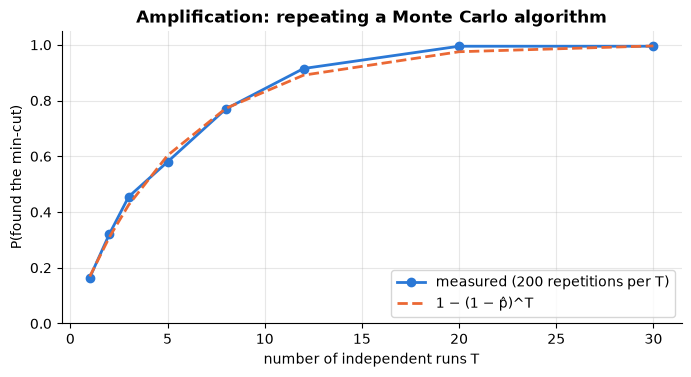

Worst-case recipe for failure <= 1/n: T = C(n,2)·ln n = 570 runs; with the measured p̂ = 0.169, only 18 runs give the same guarantee here.


In [20]:
# Amplification: probability that at least one of T runs finds the min-cut
Ts = [1, 2, 3, 5, 8, 12, 20, 30]
emp = []
for T in Ts:
    hits = 0
    for rep in range(200):
        hits += min(karger_once(n, edges, rng)[0] for _ in range(T)) == true_cut
    emp.append(hits / 200)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(Ts, emp, "o-", label="measured (200 repetitions per T)")
ax.plot(Ts, [1 - (1 - p_hat) ** T for T in Ts], "--", label="1 − (1 − p̂)^T")
ax.set(xlabel="number of independent runs T", ylabel="P(found the min-cut)",
       title="Amplification: repeating a Monte Carlo algorithm", ylim=(0, 1.05))
ax.legend(); plt.show()
T_needed = math.ceil(math.comb(n, 2) * math.log(n))
print(f"Worst-case recipe for failure <= 1/n: T = C(n,2)·ln n = {T_needed} runs; "
      f"with the measured p̂ = {p_hat:.3f}, only {math.ceil(math.log(n) / p_hat)} runs give the same guarantee here.")

**What just happened?** On this graph a single contraction run finds the 3-edge bridge cut much more often than the worst-case bound 2/(n(n−1)) ≈ 0.005, because dense clusters are hard to cut by accident. Repeating the algorithm drives the success probability towards 1 exactly as 1 − (1 − p)ᵀ predicts, and the best of 50 runs matched the deterministic Stoer–Wagner answer.

**Complexity.** One run is O(m α(n)) with union-find. The full guarantee needs O(n² log n) runs, so O(n² m log n) in total. The **Karger–Stein** recursive variant (contract to n/√2 vertices, recurse twice) reaches O(n² log³ n) total time with high success probability.

> ⚠️ **Common mistake:** amplification only works with **independent** runs. Re-running with the same random seed gives the same answer every time, so the failure probability does not shrink at all.

---
## 11. Summary table

> 💬 **In plain English:** every technique in this notebook on one page.

| Technique / structure | Type | Key bound | Section |
|---|---|---|---|
| binary counter, multipop stack | amortized (all 3 methods) | O(1) amortized per op | 1 |
| dynamic array, ×r growth | amortized | O(1) amortized append; +k growth gives Θ(n) | 2 |
| union-find, rank + compression | amortized | O(m α(n)) for m ops | 3 |
| random probing for "a" | Las Vegas / Monte Carlo | E[probes] = 2 / error 2⁻ᵏ | 4 |
| randomized quicksort | Las Vegas | E = 2(n+1)H_n − 4n ≈ 1.39 n log₂ n comparisons | 5 |
| quickselect | Las Vegas | O(n) expected, ≤ 4n compares | 5 |
| universal hashing | randomized family | Pr[collision] ≤ 1/m for every pair | 6 |
| skip list | Las Vegas | O(log n) expected per op, 2n pointers | 7 |
| treap | Las Vegas | O(log n) expected per op | 8 |
| Miller–Rabin | Monte Carlo (one-sided) | error ≤ 4⁻ᵏ, O(k log³ n) | 9 |
| Karger min-cut | Monte Carlo (one-sided) | success ≥ 2/(n(n−1)) per run | 10 |

---
## 12. 🔗 How this connects to modern AI

> 💬 **In plain English:** the same ideas (random choices, cheap-on-average structures) run inside SGD, vector search and fast PCA.

Randomness is everywhere in AI systems, for the same reasons as above: it avoids bad worst cases, it is cheap and it parallelises well.

- **Random restarts** in local search ([`classical_ai/04`](../classical_ai/04_local_search_and_optimization.ipynb)) turn hill climbing into a Las Vegas-style algorithm for N-Queens: every restart has a fixed chance p of success, so the expected number of restarts is 1/p, the same geometric distribution as in section 4.
- **Stochastic gradient descent** is a randomized algorithm: each step uses a random mini-batch, an *unbiased* estimate of the full gradient that is much cheaper to compute ([`05_Deep_Learning/02_optimizers`](../../05_Deep_Learning/02_optimizers.ipynb)). Dropout, random data augmentation and random weight initialisation are also coin flips with a purpose.
- **Random forests** ([`03_Machine_Learning/01_supervised`](../../03_Machine_Learning/01_supervised)) randomise rows (bootstrap) and features; **randomized hyperparameter search** often beats grid search.
- **Hashing and sketching:** universal hashing underlies feature hashing in ML pipelines, MinHash/LSH for near-duplicate detection in LLM training data, and Bloom filters.
- **Skip lists** sit inside the memtables of LSM-tree stores (RocksDB) used for feature stores and logs, and in Redis sorted sets used for leaderboards and rate limiters. The HNSW vector index ([`22_ML_System_Design/05_vector_databases`](../../22_ML_System_Design/05_vector_databases.ipynb)) is literally a **hierarchical skip-list-like graph**: each vector gets a random top layer with geometrically decaying probability, exactly like a skip-list node.
- **Union-find** labels connected components in images and merges duplicate entities in record linkage.
- **Randomized SVD** (Halko, Martinsson & Tropp, 2011) multiplies the matrix by a small random matrix to find its dominant subspace, and is used for PCA on large data, LSA, recommender embeddings, and low-rank compression of neural network layers (the idea behind LoRA-style low-rank factors). Let's time it against the full SVD:

In [21]:
from sklearn.utils.extmath import randomized_svd
from threadpoolctl import threadpool_limits
threadpool_limits(2)        # use 2 BLAS threads so timings are fair and the machine stays responsive

rng_np = np.random.default_rng(0)
m_rows, n_cols, true_rank = 2000, 500, 10
A = rng_np.normal(size=(m_rows, true_rank)) @ rng_np.normal(size=(true_rank, n_cols))   # low rank
A += 0.01 * rng_np.normal(size=A.shape)                                                 # plus a little noise

t0 = time.perf_counter()
U, S_full, Vt = np.linalg.svd(A, full_matrices=False)
t_full = time.perf_counter() - t0
t0 = time.perf_counter()
U_r, S_r, Vt_r = randomized_svd(A, n_components=10, n_iter=4, random_state=0)
t_rand = time.perf_counter() - t0

rel_err = np.abs(S_r - S_full[:10]) / S_full[:10]
recon_full = np.linalg.norm(A - (U[:, :10] * S_full[:10]) @ Vt[:10]) / np.linalg.norm(A)
recon_rand = np.linalg.norm(A - (U_r * S_r) @ Vt_r) / np.linalg.norm(A)
print(f"full SVD:       {t_full * 1000:7.1f} ms")
print(f"randomized SVD: {t_rand * 1000:7.1f} ms  (top 10 components only)")
print(f"max relative error in the top-10 singular values: {rel_err.max():.2e}")
print(f"relative reconstruction error, rank 10: full {recon_full:.5f} vs randomized {recon_rand:.5f}")
assert rel_err.max() < 1e-3

full SVD:         239.2 ms
randomized SVD:    30.9 ms  (top 10 components only)
max relative error in the top-10 singular values: 1.70e-15
relative reconstruction error, rank 10: full 0.00314 vs randomized 0.00314


**What just happened?** Randomized SVD recovered the top 10 singular values almost exactly (relative error far below 0.1 %) and the same rank-10 reconstruction quality, usually in a fraction of the time of the full SVD (the speed-up grows with the matrix size and depends on your machine's BLAS). The approximation is excellent here because the matrix really is (nearly) low rank; for slowly decaying spectra you add more power iterations (`n_iter`) or oversampling.

---
## Recap
- **Amortized analysis** bounds the total cost of the *worst sequence* of operations; there is no probability involved. The aggregate method sums costs, the accounting method stores credit on the data structure, and the potential method uses Φ with $\hat c_i = c_i + \Delta\Phi$, which telescopes.
- Dynamic arrays must grow by a **constant factor** (×2, ×1.5, CPython's ≈ ×1.125) to get O(1) amortized appends; growing by +k gives Θ(n²) total copies.
- **Union-find** with union by rank and path compression costs O(m α(n)), and α(n) ≤ 4 for any practical n.
- **Las Vegas** algorithms are always correct with a random running time; **Monte Carlo** algorithms have a bounded running time and a small error probability, which shrinks exponentially with independent repetition (amplification).
- Randomized **quicksort** makes about 1.39 n log₂ n comparisons in expectation on every input; **quickselect** finds the k-th smallest in O(n) expected time.
- **Universal hashing** picks the hash function at random so that no fixed input is bad: Pr[collision] ≤ 1/m.
- **Skip lists** and **treaps** are simple randomized balanced search structures with O(log n) expected operations; for moderate n, constant factors can still favour a C-backed sorted list.
- **Miller–Rabin** (error ≤ 4⁻ᵏ) and **Karger's min-cut** (success ≥ 2/(n(n−1)) per run) are classic Monte Carlo algorithms.
- AI uses all of this: SGD, random restarts, randomized SVD, LSH/MinHash, and HNSW's skip-list-style layers.

## Practice problems

**1. (Easy, conceptual)** Classify each as Las Vegas or Monte Carlo: (a) randomized quicksort, (b) Miller–Rabin, (c) a Bloom filter lookup, (d) a treap search, (e) Karger's min-cut with a fixed number of runs.

<details><summary>Show solution</summary>

(a) **Las Vegas**: always sorts correctly, time is random. (b) **Monte Carlo**, one-sided: may call a composite "prime". (c) **Monte Carlo**, one-sided: false positives possible, never false negatives. (d) **Las Vegas**: the answer is always right, only the tree shape (and so the time) is random. (e) **Monte Carlo**: the run time is fixed, and it may return a cut that is not minimum.

</details>

**2. (Easy, conceptual)** A dynamic array doubles when full and **halves when it becomes half full**. Show a sequence of operations with Θ(n) amortized cost per operation, and give the standard fix.

<details><summary>Show solution</summary>

Fill the array to exactly capacity c = n (n a power of 2). Then repeat: push (forces doubling to 2n: copy n), pop (size is back to n = half of 2n: halve, copy n), push (double again), … Every operation copies Θ(n) elements, so m operations cost Θ(mn).
**Fix:** halve only when the array is **¼ full**. After any resize the array is exactly half full, so Θ(capacity) cheap operations must happen before the next resize, and a potential argument gives O(1) amortized (CLRS §16.4).

</details>

**3. (Medium, coding)** Implement a FIFO queue with two stacks and prove that every operation is O(1) amortized. Count element moves to check your proof.

<details><summary>Show solution</summary>

```python
class TwoStackQueue:
    """FIFO queue from two stacks. Counts element moves to check the amortized bound."""
    def __init__(self):
        self.inbox, self.outbox, self.moves = [], [], 0
    def enqueue(self, x):
        self.inbox.append(x); self.moves += 1
    def dequeue(self):
        if not self.outbox:
            while self.inbox:                       # pour inbox into outbox (reverses the order)
                self.outbox.append(self.inbox.pop()); self.moves += 2
        self.moves += 1
        return self.outbox.pop()
```
**Accounting proof:** charge `enqueue` 4 units: 1 for the push onto `inbox`, and 3 stored as credit on the element, which later pay for its pop from `inbox`, its push onto `outbox` and its final pop. Every element moves inbox → outbox at most once, so the credit never runs out, and every operation is O(1) amortized. With this move-counting, the total is ≤ 4 × (number of operations); the solution was tested on 20,000 random operations against `collections.deque`.

</details>

**4. (Medium, conceptual)** How many independent runs of Karger's algorithm guarantee a failure probability of at most 1 % on a graph with n = 50 vertices, using only the worst-case bound?

<details><summary>Show solution</summary>

One run succeeds with probability p ≥ 2/(n(n−1)) = 2/2450 = 1/1225. We need (1 − p)ᵀ ≤ e^{−pT} ≤ 0.01, i.e. T ≥ ln(100)/p = 4.605 × 1225 ≈ **5,642 runs** (rounding up). In practice far fewer are needed, as section 10 showed, but this is the guarantee for *every* graph.

</details>

**5. (Medium, coding)** Freivalds' algorithm: given n×n matrices A, B, C, check whether AB = C in O(n²) time per round (computing AB directly costs O(n³), or O(n^2.37) with the best known methods). Implement it and test it.

<details><summary>Show solution</summary>

```python
import numpy as np

def freivalds(A, B, C, k=20, rng=None):
    """Monte Carlo check of A @ B == C in O(k n^2). Never rejects a correct C;
    accepts a wrong C with probability <= 2**-k."""
    rng = rng or np.random.default_rng()
    n = C.shape[1]
    for _ in range(k):
        r = rng.integers(0, 2, size=n)              # random 0/1 vector
        if not np.array_equal(A @ (B @ r), C @ r):  # three matrix-vector products: O(n^2)
            return False
    return True
```
If AB ≠ C, let D = AB − C ≠ 0. For a random 0/1 vector r, Pr[Dr = 0] ≤ ½, so a wrong C survives k rounds with probability ≤ 2⁻ᵏ. A correct C always passes (one-sided Monte Carlo). Tested on 50 random correct and corrupted products.

</details>

**6. (Medium, conceptual)** In a skip list with promotion probability p, what is the expected number of nodes at level i, the expected total number of pointers, and the expected number of levels? What changes for p = ¼?

<details><summary>Show solution</summary>

A node reaches level i (counting level 0 as the bottom) with probability pⁱ, so the expected number of nodes at level i is n·pⁱ. Total pointers: n(1 + p + p² + …) = **n/(1 − p)**, i.e. 2n for p = ½ and 1.33n for p = ¼. The number of levels is about **log_{1/p} n** (the level where n·pⁱ ≈ 1). A search does about (1/p)·log_{1/p} n expected comparisons. With p = ¼ the structure uses less memory and has half as many levels, but scans about twice as far per level; Pugh recommends p = ¼ when memory matters.

</details>

**7. (Medium, coding)** Implement union-find with **union by size** and **path halving**, and use it to count connected components. Test it against networkx.

<details><summary>Show solution</summary>

```python
class DSU:
    """Union by size + path halving (a one-pass variant of path compression)."""
    def __init__(self, n):
        self.parent = list(range(n)); self.size = [1] * n; self.count = n
    def find(self, x):
        while self.parent[x] != x:
            self.parent[x] = self.parent[self.parent[x]]   # path halving: skip to grandparent
            x = self.parent[x]
        return x
    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra == rb:
            return False
        if self.size[ra] < self.size[rb]:
            ra, rb = rb, ra                                  # attach the smaller tree
        self.parent[rb] = ra; self.size[ra] += self.size[rb]; self.count -= 1
        return True

def count_components(n, edges):
    d = DSU(n)
    for u, v in edges:
        d.union(u, v)
    return d.count
```
Path halving makes every node on the find path point to its grandparent, in one pass without recursion; together with union by size it has the same O(α(n)) amortized bound as full path compression (Tarjan & van Leeuwen 1984). Tested on 100 random graphs against `nx.number_connected_components`.

</details>

**8. (Hard, conceptual)** Prove that in randomized quicksort the i-th and j-th smallest elements (i < j) are compared with probability exactly 2/(j − i + 1), and use it to show E[comparisons] = O(n log n).

<details><summary>Show solution</summary>

Let Z_ij = {z_i, …, z_j}, which has j − i + 1 elements. Until some element of Z_ij becomes a pivot, all of Z_ij stays in the same sub-array. When the first pivot from Z_ij is chosen, each of its elements is equally likely to be that pivot. If it is z_i or z_j, those two are compared (the pivot is compared with everything in its sub-array). If it is anything strictly in between, z_i and z_j go to different sides and are never compared. So Pr = 2/(j − i + 1).
By linearity of expectation, E[X] = Σ_{i<j} 2/(j−i+1). Substituting k = j − i: E[X] = Σ_{i=1}^{n−1} Σ_{k=1}^{n−i} 2/(k+1) < Σ_{i=1}^{n} 2H_n = **O(n log n)**. The exact sum is 2(n+1)H_n − 4n, which section 5 matched experimentally.

</details>

## Further reading (additional learning resources)
- Cormen, Leiserson, Rivest, Stein, *Introduction to Algorithms* (CLRS, 4th ed., 2022): ch. 16 (amortized analysis), ch. 19 (disjoint sets), §7.3–7.4 (randomized quicksort), §9.2 (randomized select), §11.3 (universal hashing).
- Motwani & Raghavan, *Randomized Algorithms* (Cambridge, 1995): ch. 1 (Karger's min-cut, Las Vegas vs Monte Carlo), ch. 8 (skip lists, treaps), ch. 14 (primality).
- Mitzenmacher & Upfal, *Probability and Computing* (2nd ed., 2017): ch. 1–2, 5 and 13.
- Kleinberg & Tardos, *Algorithm Design*, ch. 13 (randomized algorithms).
- W. Pugh, "Skip Lists: A Probabilistic Alternative to Balanced Trees", *CACM* 1990.
- Halko, Martinsson & Tropp, "Finding Structure with Randomness", *SIAM Review* 2011 (randomized SVD).
- MIT OCW 6.046J *Design and Analysis of Algorithms* (lectures on amortization, randomization and skip lists): https://ocw.mit.edu/courses/6-046j-design-and-analysis-of-algorithms-spring-2015/
- GeeksforGeeks: [Randomized Algorithms](https://www.geeksforgeeks.org/randomized-algorithms/) and [Amortized analysis](https://www.geeksforgeeks.org/introduction-to-amortized-analysis/).

## Next notebook
➡️ [02 · NP-completeness and reductions](02_np_completeness_and_reductions.ipynb): which problems are probably *not* solvable in polynomial time, how to prove it with reductions, and how a SAT solver works.